In [1]:
# Setup - install the Kaggle download tool, import libraries, set a random seed for reproducibility, and check that a GPU is available
!pip -q install kagglehub

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Download the Garbage Classification dataset from Kaggle and find the folder that contains the six class folders
import kagglehub
BASE = kagglehub.dataset_download("asdasdasasdas/garbage-classification")
print("Downloaded to:", BASE)
# The class folders are nested inside the download, so search for them
EXPECTED = {'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash'}
ROOT = None
for dirpath, dirnames, _ in os.walk(BASE):
    if EXPECTED.issubset({d.lower() for d in dirnames}):
        ROOT = dirpath
        break
assert ROOT is not None, "Class folders not found"
print("Class folders found in:", ROOT)
print(sorted(d for d in os.listdir(ROOT) if os.path.isdir(os.path.join(ROOT, d))))

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded to: /kaggle/input/garbage-classification
Class folders found in: /kaggle/input/garbage-classification/Garbage classification/Garbage classification
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Total images: 2527 | Classes: 6
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


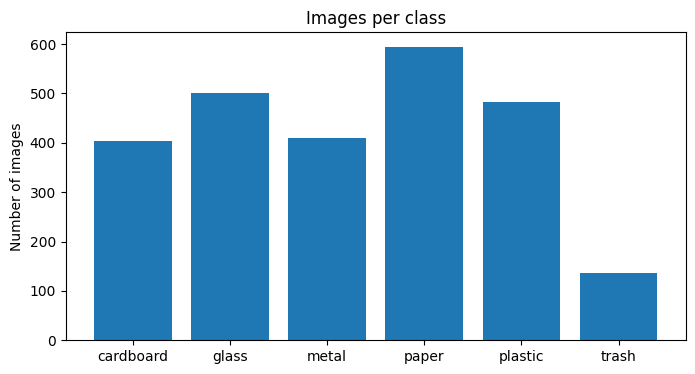

label
cardboard    403
glass        501
metal        410
paper        594
plastic      482
trash        137
Name: count, dtype: int64


In [3]:
# Build a table of image paths and labels, convert class names to numbers (0-5), and plot the number of images per class
rows = []
for cls in sorted(os.listdir(ROOT)):
  cdir = os.path.join(ROOT, cls)
  if os.path.isdir(cdir):
    for f in os.listdir(cdir):
      if f.lower().endswith(('.jpg', '.jpeg', '.png')):
        rows.append((os.path.join(cdir, f), cls))
  df = pd.DataFrame(rows, columns=['path', 'label'])
  CLASS_NAMES = sorted(df['label'].unique())
  NUM_CLASSES = len(CLASS_NAMES)
  label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
df['y'] = df['label'].map(label_to_idx)

print("Total images:", len(df), "| Classes:", NUM_CLASSES)
print(CLASS_NAMES)

counts = df['label'].value_counts().sort_index()
plt.figure(figsize=(8,4))
plt.bar(counts.index, counts.values)
plt.ylabel('Number of images'); plt.title('Images per class')
plt.show()
print(counts)

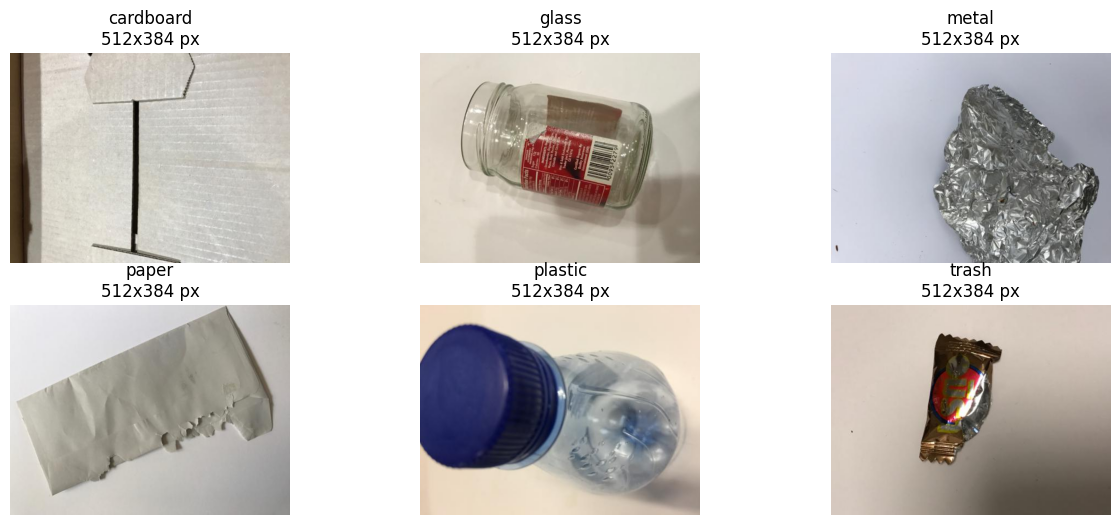

In [4]:
# Display one sample image from each of the six classes

# Pick one random image from each class (random_state makes the choice repeatable)
samples = df.groupby('label').sample(1, random_state=SEED)

plt.figure(figsize=(15, 6))                      # create a large figure to hold the images
for i, (_, row) in enumerate(samples.iterrows()):
    img = Image.open(row['path'])                # open the image file
    plt.subplot(2, 3, i + 1)                     # place it in a 2-row by 3-column grid
    plt.imshow(img); plt.axis('off')             # show the image and hide the axes
    plt.title(f"{row['label']}\n{img.size[0]}x{img.size[1]} px")   # class name and original size
plt.show()

In [5]:
# Split the Data into training (70%), validation (15%) and test (15%) sets
#First split 70% for training, 30% held back temporarily
#Stratify keeps the class proportions the same in every set, so small classes like trash appear in all of them
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['y'], random_state=SEED)
#Second split: divide the held-back 30% equally into validation(15%) and test(15%)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['y'], random_state=SEED)
print("Train:", len(train_df), "| Validation:", len(val_df))
#Table showing how many images of each class ended up in each set
pd.DataFrame({'train': train_df['label'].value_counts(),
'val': val_df['label'].value_counts(),
'test': test_df['label'].value_counts()}).sort_index()

Train: 1768 | Validation: 379


,train,val,test
label,,,
cardboard,282,61,60
glass,350,75,76
metal,287,61,62
paper,416,89,89
plastic,337,72,73
trash,96,21,20


In [6]:
# Cell 6: Resize every image to 128x128 and normalize pixel values to the range 0-1

IMG_SIZE = 128   # all images will be made 128 x 128 pixels

def load_images(frame):
    # Create an empty array to hold all images: (number of images, height, width, 3 colour channels)
    X = np.empty((len(frame), IMG_SIZE, IMG_SIZE, 3), dtype='float32')
    for i, p in enumerate(frame['path']):
        img = Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE))   # open, force 3 colour channels, resize
        X[i] = np.asarray(img, dtype='float32') / 255.0                   # convert to numbers and scale 0-255 -> 0-1
    return X, frame['y'].values                                          # images and their numeric labels

# Apply the function to each of the three sets
X_train, y_train = load_images(train_df)
X_val,   y_val   = load_images(val_df)
X_test,  y_test  = load_images(test_df)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

X_train: (1768, 128, 128, 3) | X_val: (379, 128, 128, 3) | X_test: (380, 128, 128, 3)
Pixel range: 0.0 to 1.0


In [7]:
#Build the CNN archirtecture
from tensorflow.keras import layers, models
model = models.Sequential ([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),      #Input 128 by 128 color images
    # Data augmentation: random changes to training images (only active during training)
    layers.RandomFlip("horizontal"),                          #randomly mirror images
    layers.RandomRotation(0.1),                       #randomly rotate by upto 36 degrees
    layers.RandomZoom(0.1),     #randomly rotate in or out by upto 10%

    #Convolution block 1: learn simple features (edges, colours)
    layers.Conv2D(32,(3, 3), activation = 'relu', padding = 'same'),
    layers.MaxPooling2D((2,2)),

    #Convolution block 2: combine simple features into textures and shapes
    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    #Convolution block 3: learn higher-level patterns (parts of objects)
    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.MaxPooling2D((2,2)),

    #Fully connected classifier part
    layers. Flatten(),   #turn the 16by16by128 feature maps into one long vector
    layers.Dense(128, activation='relu'),    #Combine all features to make a decision
    layers.Dropout(0.5),        #randomly switch off 50% of neurons to reduce overfitting
    layers.Dense(NUM_CLASSES, activation='softmax')       #output probability for each of the 6 classes
])
model.summary()        # print every layer, its shape and number of parameters

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,454 (16.36 MB)

 Trainable params: 4,288,454 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Cell 8: Compile (choose loss, optimizer, metric) and train the model

from sklearn.utils.class_weight import compute_class_weight

# Class weights: give the small classes (like trash) more importance during training,
# so the model doesn't ignore them just because it sees fewer examples
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print("Class weights:", class_weights)

# Compile: tell the model how to learn and how to measure progress
model.compile(
    optimizer='adam',                          # Adam: adjusts the learning rate automatically for each weight
    loss='sparse_categorical_crossentropy',    # loss for multi-class problems where labels are integers (0-5)
    metrics=['accuracy']                       # report the percentage of correct predictions
)

# Early stopping: stop if validation loss hasn't improved for 5 epochs, and keep the best version of the model
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),            # check progress on the validation set after every epoch
    epochs=30,                                 # maximum number of passes through the training data
    batch_size=32,                             # update the weights after every 32 images
    class_weight=class_weights,
    callbacks=[early_stop]
)

Class weights: {0: np.float64(1.044917257683215), 1: np.float64(0.8419047619047619), 2: np.float64(1.0267131242740999), 3: np.float64(0.7083333333333334), 4: np.float64(0.874381800197824), 5: np.float64(3.0694444444444446)}
Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.2766 - loss: 1.7663 - val_accuracy: 0.3113 - val_loss: 1.6399
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.3479 - loss: 1.5615 - val_accuracy: 0.4037 - val_loss: 1.4914
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3620 - loss: 1.4796 - val_accuracy: 0.3799 - val_loss: 1.4801
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4157 - loss: 1.3899 - val_accuracy: 0.4828 - val_loss: 1.3421
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4389 - loss: 1.3655 - val_accuracy: 0.4749 - val_loss: 1.3842
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4813 - loss: 1.3151 - val_accuracy: 0.5277 - val_loss: 1.2848
Epoch 7/30
56/

In [9]:
# Improved model - same structure as before, plus Batch Normalization, lighter augmentation and longer training

def conv_block(filters):
    # One convolution block: convolution -> batch normalization -> ReLU -> max pooling
    return [
        layers.Conv2D(filters, (3, 3), padding='same'),   # learn filters (no activation yet)
        layers.BatchNormalization(),                       # normalize the outputs so training is faster and more stable
        layers.Activation('relu'),                         # ReLU activation
        layers.MaxPooling2D((2, 2)),                       # halve the image size
    ]

model2 = models.Sequential(
    [layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
     layers.RandomFlip("horizontal"),                      # lighter augmentation than before
     layers.RandomRotation(0.05),
     layers.RandomZoom(0.05)]
    + conv_block(32) + conv_block(64) + conv_block(128)
    + [layers.Flatten(),
       layers.Dense(128, activation='relu'),
       layers.Dropout(0.4),                                # slightly less dropout than before
       layers.Dense(NUM_CLASSES, activation='softmax')]
)

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

# Stop if validation loss hasn't improved for 10 epochs, and go back to the best version of the model
early_stop2 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# Halve the learning rate if validation loss stalls for 4 epochs (helps the model settle on a better solution)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)

history2 = model2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,                                             # more epochs, since the first model was still improving
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop2, reduce_lr]
)

Epoch 1/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.2687 - loss: 4.7280 - val_accuracy: 0.2375 - val_loss: 1.7826 - learning_rate: 0.0010
Epoch 2/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.3003 - loss: 1.6684 - val_accuracy: 0.0580 - val_loss: 2.0121 - learning_rate: 0.0010
Epoch 3/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.3462 - loss: 1.6769 - val_accuracy: 0.2797 - val_loss: 1.7633 - learning_rate: 0.0010
Epoch 4/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.3416 - loss: 1.6761 - val_accuracy: 0.3193 - val_loss: 1.7491 - learning_rate: 0.0010
Epoch 5/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.3575 - loss: 1.6648 - val_accuracy: 0.2744 - val_loss: 1.7500 - learning_rate: 0.0010
Epoch 6/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.3445 - loss: 1.6682 - val_accuracy: 0.3298 - val_loss: 1.6869 - learning_rate: 0.0010
Epoch 7/60
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.3586 - loss: 1.6425 - val_acc

In [10]:
# Cell 10: Continue training the ORIGINAL model (the first one) for more epochs

# Stop if validation loss hasn't improved for 8 epochs, and go back to the best version of the model
early_stop3 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
# Halve the learning rate if validation loss stalls for 4 epochs
reduce_lr3 = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)

# model.fit continues from the weights the model already has, so this is extra training, not a restart
history_cont = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,                                   # up to 40 more passes through the training data
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop3, reduce_lr3]
)

Epoch 1/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.6414 - loss: 0.9184 - val_accuracy: 0.6280 - val_loss: 0.9500 - learning_rate: 0.0010
Epoch 2/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6606 - loss: 0.8726 - val_accuracy: 0.6095 - val_loss: 1.0169 - learning_rate: 0.0010
Epoch 3/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6499 - loss: 0.9058 - val_accuracy: 0.6359 - val_loss: 0.9041 - learning_rate: 0.0010
Epoch 4/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6414 - loss: 0.9197 - val_accuracy: 0.6359 - val_loss: 0.9239 - learning_rate: 0.0010
Epoch 5/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6708 - loss: 0.8490 - val_accuracy: 0.6385 - val_loss: 0.9460 - learning_rate: 0.0010
Epoch 6/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6804 - loss: 0.8323 - val_accuracy: 0.6491 - val_loss: 0.9531 - learning_rate: 0.0010
Epoch 7/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6719 - loss: 0.8462 - val_acc

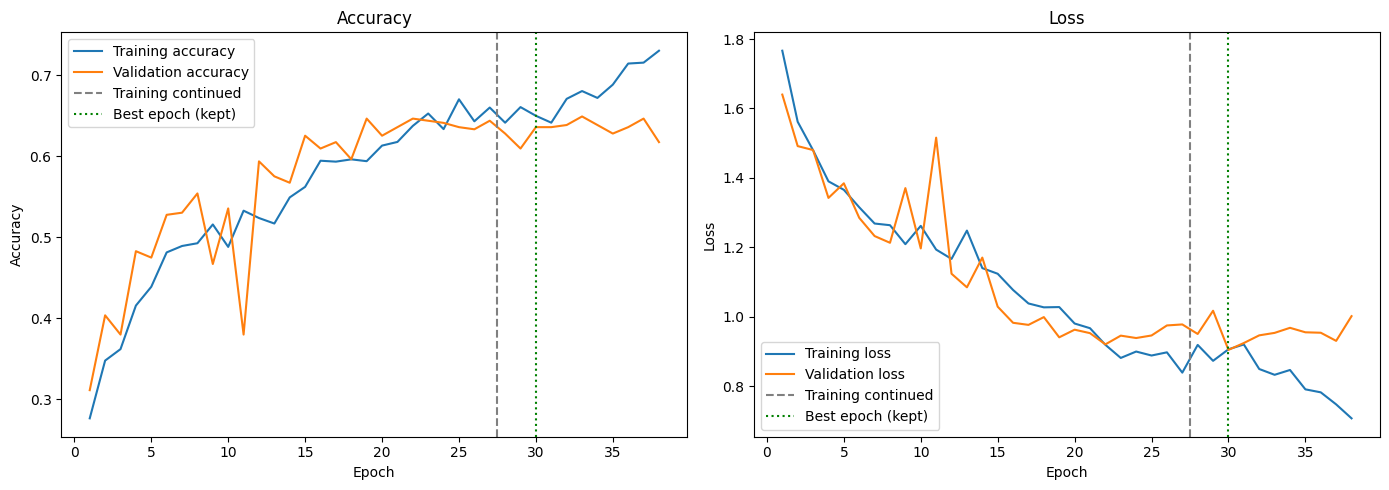

Best epoch: 30 | Validation accuracy there: 0.6359


In [11]:
# Plot training and validation accuracy and loss
# We join the first training run and the continued run so the graph shows the whole training process

acc      = history.history['accuracy']      + history_cont.history['accuracy']
val_acc  = history.history['val_accuracy']  + history_cont.history['val_accuracy']
loss     = history.history['loss']          + history_cont.history['loss']
val_loss = history.history['val_loss']      + history_cont.history['val_loss']

epochs_range = range(1, len(acc) + 1)
first_run_len = len(history.history['accuracy'])        # epoch where the continued training began
best_epoch = int(np.argmin(val_loss)) + 1               # epoch with the lowest validation loss (the weights we kept)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left graph: accuracy
axes[0].plot(epochs_range, acc, label='Training accuracy')
axes[0].plot(epochs_range, val_acc, label='Validation accuracy')
axes[0].axvline(first_run_len + 0.5, color='grey', linestyle='--', label='Training continued')   # marks the restart
axes[0].axvline(best_epoch, color='green', linestyle=':', label='Best epoch (kept)')
axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].legend()

# Right graph: loss
axes[1].plot(epochs_range, loss, label='Training loss')
axes[1].plot(epochs_range, val_loss, label='Validation loss')
axes[1].axvline(first_run_len + 0.5, color='grey', linestyle='--', label='Training continued')
axes[1].axvline(best_epoch, color='green', linestyle=':', label='Best epoch (kept)')
axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()

plt.tight_layout()
plt.show()
print("Best epoch:", best_epoch, "| Validation accuracy there:", round(val_acc[best_epoch - 1], 4))

Test accuracy: 0.6447 | Test loss: 1.0069

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
              precision    recall  f1-score   support

   cardboard      0.828     0.800     0.814        60
       glass      0.667     0.500     0.571        76
       metal      0.681     0.516     0.587        62
       paper      0.688     0.742     0.714        89
     plastic      0.776     0.616     0.687        73
       trash      0.250     0.800     0.381        20

    accuracy                          0.645       380
   macro avg      0.648     0.662     0.626       380
weighted avg      0.698     0.645     0.658       380



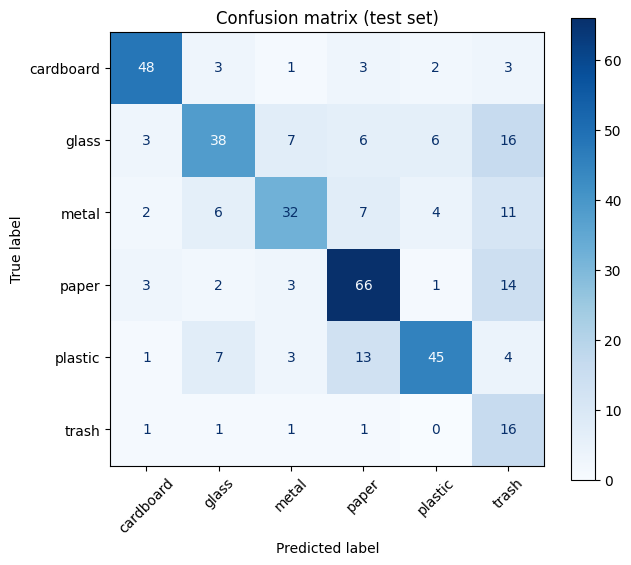

In [12]:
# Evaluate the final model on the unseen test set

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Overall test accuracy and loss
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}\n")

# Predicted probabilities for every test image, then pick the class with the highest probability
probs = model.predict(X_test)
y_pred = np.argmax(probs, axis=1)

# Precision, recall and F1-score for each class
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title('Confusion matrix (test set)')
plt.show()

# Save the trained model so we don't lose it if Colab disconnects
model.save('waste_cnn.keras')

Mounted at /content/drive
Found 6 images: ['cardboard_box.jpg', 'glass_jar.jpg', 'metal_can.jpg', 'paper_crumpled.jpg', 'plastic_bottle.jpg', 'trash_wrapper.jpg']


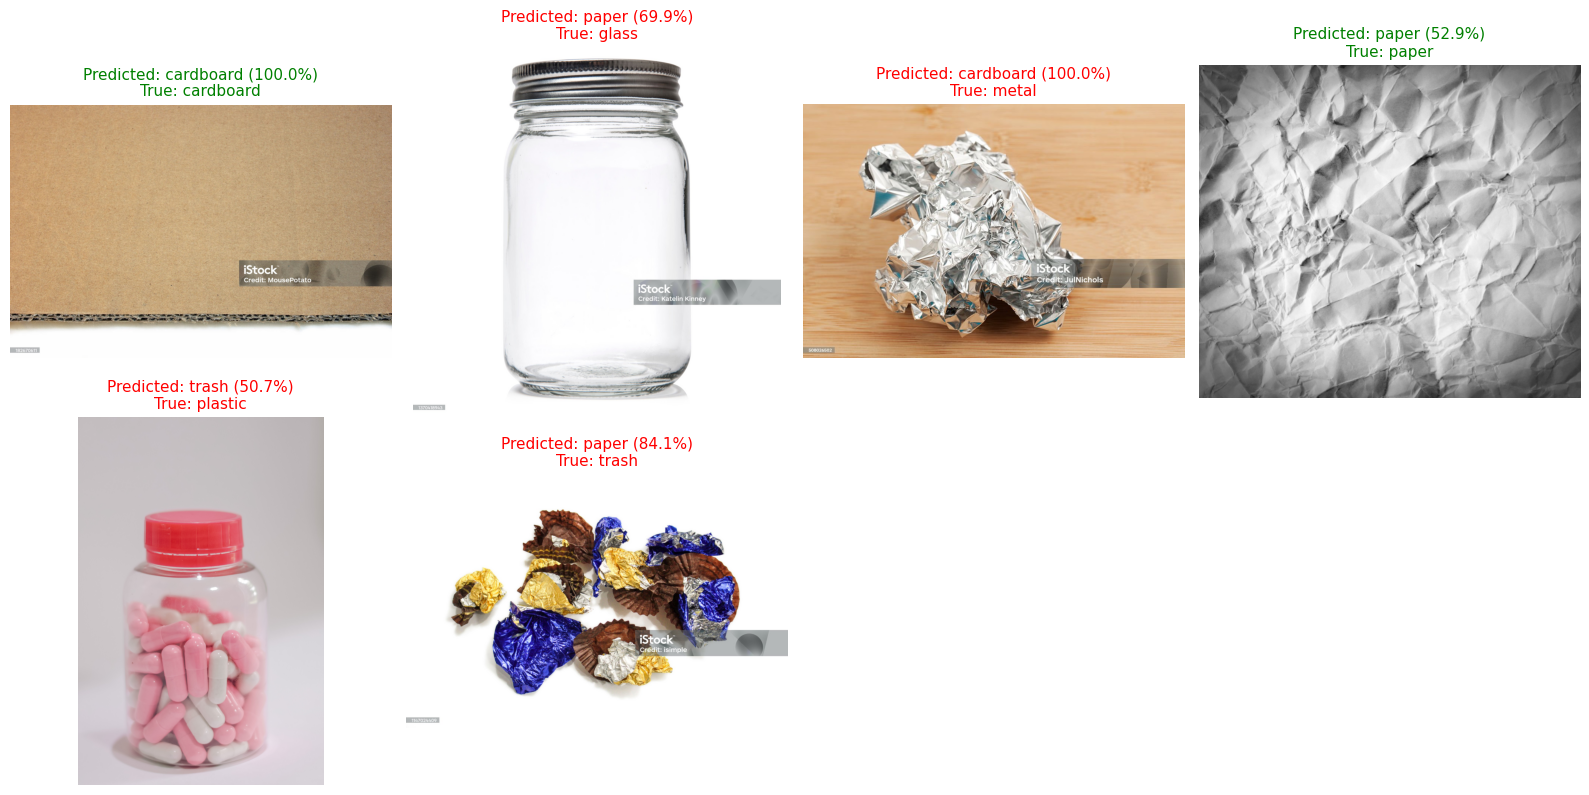

2 of 6 correct


In [14]:
# Predict new images stored in Google Drive. The true class is read from the start of each file name (e.g. glass_jar.jpg -> glass)

import os, glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps
from google.colab import drive

drive.mount('/content/drive')                          # connect Colab to your Google Drive (a permission pop-up appears)
FOLDER = '/content/drive/MyDrive/waste_test'           # the Drive folder that holds your six photos

# If Colab has forgotten the model or settings, restore them (class order is alphabetical, as in training)
IMG_SIZE = 128
CLASS_NAMES = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
if 'model' not in globals():
    model = tf.keras.models.load_model('/content/waste_cnn.keras')

# Find image files whose names start with one of the class names
paths = sorted(p for p in glob.glob(os.path.join(FOLDER, '*'))
               if p.lower().endswith(('.jpg', '.jpeg', '.png'))
               and os.path.basename(p).split('_')[0].lower() in CLASS_NAMES)
print("Found", len(paths), "images:", [os.path.basename(p) for p in paths])

n = len(paths)
rows = max(1, (n + 3) // 4)                # 4 images per row
plt.figure(figsize=(16, 4 * rows))
correct = 0

for i, path in enumerate(paths):
    name = os.path.basename(path)
    true = name.split('_')[0].lower()                                   # true class = text before the first underscore
    img = ImageOps.exif_transpose(Image.open(path)).convert('RGB')      # fix rotation and force 3 colour channels
    x = np.asarray(img.resize((IMG_SIZE, IMG_SIZE)), dtype='float32') / 255.0   # same preprocessing as training
    probs = model.predict(x[np.newaxis, ...], verbose=0)[0]             # 6 probabilities, one per class
    pred = int(np.argmax(probs))                                        # class with the highest probability
    ok = CLASS_NAMES[pred] == true
    correct += ok
    plt.subplot(rows, 4, i + 1)
    plt.imshow(img); plt.axis('off')
    plt.title(f"Predicted: {CLASS_NAMES[pred]} ({probs[pred] * 100:.1f}%)\nTrue: {true}",
              color='green' if ok else 'red', fontsize=11)             # green = correct, red = wrong

plt.tight_layout()
plt.show()
print(f"{correct} of {n} correct")

In [15]:
# For each uploaded image, print the probability the model gave to every class

for path in paths:
    name = os.path.basename(path)
    img = ImageOps.exif_transpose(Image.open(path)).convert('RGB')
    x = np.asarray(img.resize((IMG_SIZE, IMG_SIZE)), dtype='float32') / 255.0
    probs = model.predict(x[np.newaxis, ...], verbose=0)[0]
    # list the classes from most to least likely
    ranked = sorted(zip(CLASS_NAMES, probs), key=lambda t: -t[1])
    print(name, '->', ', '.join(f"{c} {p * 100:.1f}%" for c, p in ranked))

cardboard_box.jpg -> cardboard 100.0%, plastic 0.0%, metal 0.0%, glass 0.0%, paper 0.0%, trash 0.0%
glass_jar.jpg -> paper 69.9%, plastic 25.1%, glass 3.5%, cardboard 1.0%, metal 0.5%, trash 0.0%
metal_can.jpg -> cardboard 100.0%, glass 0.0%, metal 0.0%, plastic 0.0%, paper 0.0%, trash 0.0%
paper_crumpled.jpg -> paper 52.9%, plastic 24.0%, glass 9.7%, cardboard 6.3%, metal 5.3%, trash 1.8%
plastic_bottle.jpg -> trash 50.7%, cardboard 15.3%, paper 14.1%, plastic 7.3%, glass 7.2%, metal 5.5%
trash_wrapper.jpg -> paper 84.1%, trash 8.1%, metal 6.9%, cardboard 0.6%, plastic 0.3%, glass 0.1%
